# Mini Project 1

## Question

Do word frequencies show differences between books written by the same author
and books written by different authors?

For the same author comparison, I will compare *The Great Gatsby* and
*This Side of Paradise* by F. Scott Fitzgerald.

For the different author comparison, I will compare *The Great Gatsby*
by F. Scott Fitzgerald with *Pride and Prejudice* by Jane Austen.

I will then look for words that are used more frequently by Fitzgerald
than Austen and words that are used more frequently by Austen than Fitzgerald.

## Data Sources

All three books are from Project Gutenberg:

1. *The Great Gatsby* by F. Scott Fitzgerald - Project Gutenberg #64317
2. *This Side of Paradise* by F. Scott Fitzgerald - Project Gutenberg #805
3. *Pride and Prejudice* by Jane Austen - Project Gutenberg #1342

## Approach

1. Download the three books from Project Gutenberg.
2. Convert the text to lowercase and clean the words.
3. Remove basic English stop words.
4. Calculate the word frequencies for each book.
5. Compare *The Great Gatsby* with *This Side of Paradise*.
6. Compare *The Great Gatsby* with *Pride and Prejudice*.
7. Compare normalized word frequencies to find words preferred by each author.
8. Visualize the results using graphs.

## Potential Problems

1. The books have different lengths, which may affect actual word counts.
2. Character names may appear as some of the most common words.
3. Common English words may hide more meaningful differences between the books.

In [1]:
import requests
import re
import operator
from collections import Counter
import matplotlib.pyplot as plt

In [2]:
gatsby_url = "https://www.gutenberg.org/cache/epub/64317/pg64317.txt"
paradise_url = "https://www.gutenberg.org/cache/epub/805/pg805.txt"
pride_url = "https://www.gutenberg.org/cache/epub/1342/pg1342.txt"

gatsby_text = requests.get(gatsby_url).text
paradise_text = requests.get(paradise_url).text
pride_text = requests.get(pride_url).text

print("The Great Gatsby:", len(gatsby_text), "characters")
print("This Side of Paradise:", len(paradise_text), "characters")
print("Pride and Prejudice:", len(pride_text), "characters")

The Great Gatsby: 296899 characters
This Side of Paradise: 551371 characters
Pride and Prejudice: 763082 characters


In [3]:
def remove_gutenberg_header_footer(text):
    start = re.search(
        r"\*\*\* START OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    end = re.search(
        r"\*\*\* END OF THE PROJECT GUTENBERG EBOOK.*?\*\*\*",
        text,
        re.IGNORECASE
    )

    if start:
        text = text[start.end():]

    if end:
        text = text[:end.start()]

    return text

gatsby_text = remove_gutenberg_header_footer(gatsby_text)
paradise_text = remove_gutenberg_header_footer(paradise_text)
pride_text = remove_gutenberg_header_footer(pride_text)

print("Gatsby cleaned:", len(gatsby_text))
print("Paradise cleaned:", len(paradise_text))
print("Pride and Prejudice cleaned:", len(pride_text))

Gatsby cleaned: 278100
Paradise cleaned: 532567
Pride and Prejudice cleaned: 744280


In [4]:
stop_words = {
    "the", "and", "to", "of", "a", "in", "i", "that", "was",
    "he", "she", "it", "his", "her", "you", "as", "had", "with",
    "for", "at", "on", "is", "be", "but", "not", "my", "me",
    "we", "they", "this", "so", "by", "from", "or", "an",
    "have", "has", "were", "been", "are", "their", "there"
}

def clean_text(text):
    text = text.lower()

    words = re.findall(r"[a-z]+", text)

    clean_words = []

    for word in words:
        if word not in stop_words and len(word) > 1:
            clean_words.append(word)

    return clean_words

gatsby_words = clean_text(gatsby_text)
paradise_words = clean_text(paradise_text)
pride_words = clean_text(pride_text)

print("Great Gatsby words:", len(gatsby_words))
print("This Side of Paradise words:", len(paradise_words))
print("Pride and Prejudice words:", len(pride_words))

Great Gatsby words: 28998
This Side of Paradise words: 50754
Pride and Prejudice words: 72616


In [5]:
gatsby_counts = Counter(gatsby_words)
paradise_counts = Counter(paradise_words)
pride_counts = Counter(pride_words)

print("THE GREAT GATSBY")
print(gatsby_counts.most_common(15))

print("\nTHIS SIDE OF PARADISE")
print(paradise_counts.most_common(15))

print("\nPRIDE AND PREJUDICE")
print(pride_counts.most_common(15))

THE GREAT GATSBY
[('him', 278), ('gatsby', 265), ('said', 235), ('all', 222), ('out', 213), ('up', 191), ('tom', 191), ('daisy', 186), ('into', 168), ('one', 154), ('about', 151), ('if', 149), ('when', 146), ('what', 146), ('then', 144)]

THIS SIDE OF PARADISE
[('amory', 894), ('him', 424), ('one', 370), ('all', 365), ('what', 280), ('up', 234), ('out', 234), ('if', 230), ('like', 230), ('when', 219), ('man', 213), ('into', 213), ('don', 206), ('said', 200), ('do', 197)]

PRIDE AND PREJUDICE
[('mr', 808), ('him', 777), ('all', 651), ('elizabeth', 645), ('which', 568), ('could', 531), ('no', 510), ('very', 505), ('what', 493), ('would', 485), ('your', 455), ('them', 445), ('darcy', 432), ('will', 430), ('said', 406)]


# 1. Same Author Comparison

For the first comparison, I compared *The Great Gatsby* and
*This Side of Paradise*. Both novels were written by F. Scott Fitzgerald.

The graphs below show the 15 most frequent words in each novel after
cleaning the text and removing common stop words.

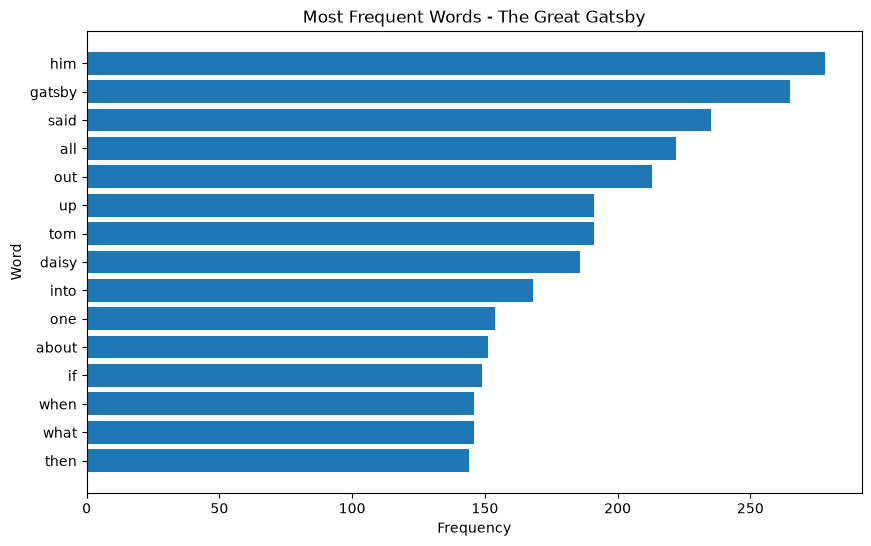

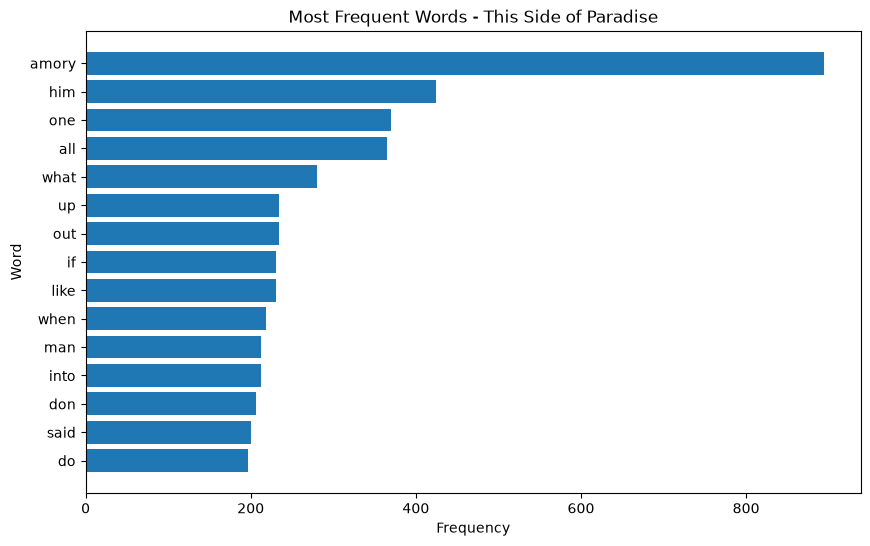

In [6]:
def plot_words(counts, title):
    top_words = counts.most_common(15)

    words = [item[0] for item in top_words]
    frequencies = [item[1] for item in top_words]

    plt.figure(figsize=(10, 6))
    plt.barh(words[::-1], frequencies[::-1])
    plt.xlabel("Frequency")
    plt.ylabel("Word")
    plt.title(title)
    plt.show()

plot_words(
    gatsby_counts,
    "Most Frequent Words - The Great Gatsby"
)

plot_words(
    paradise_counts,
    "Most Frequent Words - This Side of Paradise"
)

# 2. Different Author Comparison

For the second comparison, I compared *The Great Gatsby* by
F. Scott Fitzgerald with *Pride and Prejudice* by Jane Austen.

This compares word usage between two different authors.

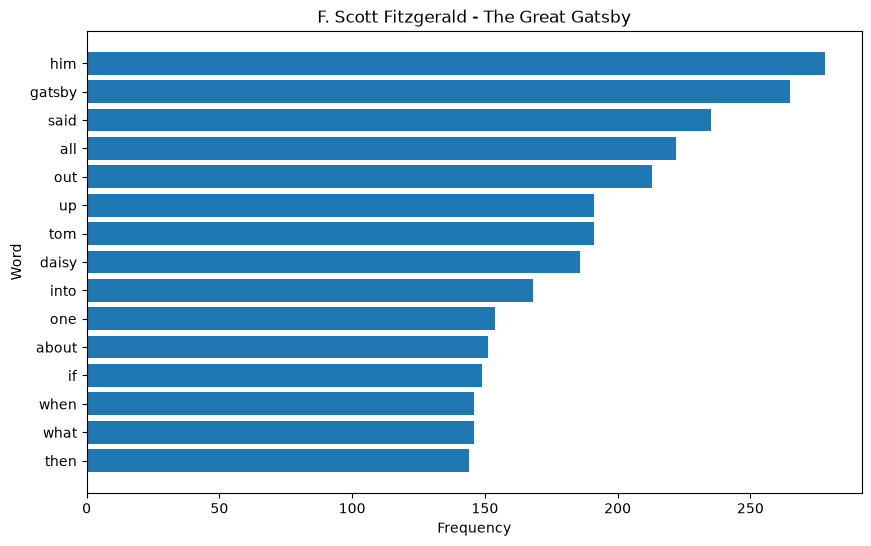

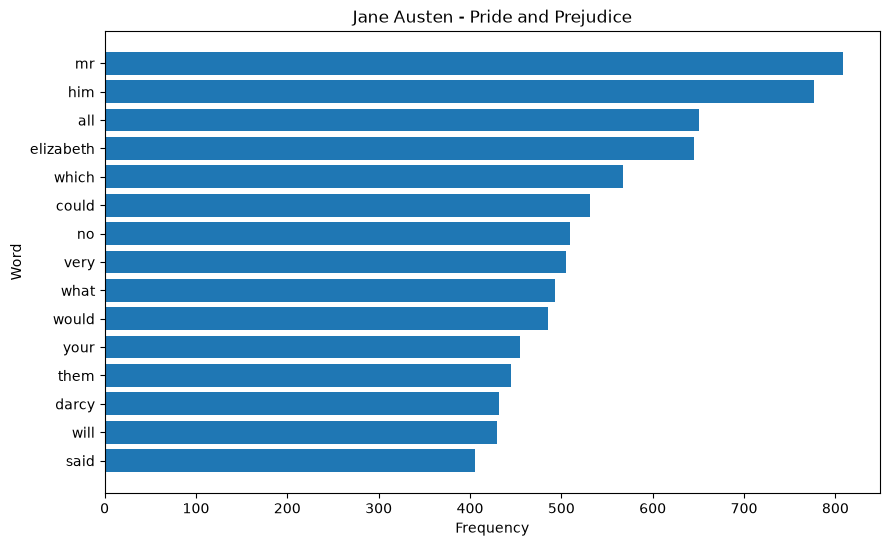

In [7]:
plot_words(
    gatsby_counts,
    "F. Scott Fitzgerald - The Great Gatsby"
)

plot_words(
    pride_counts,
    "Jane Austen - Pride and Prejudice"
)

In [8]:
def normalized_frequency(counts, total_words, word):
    return (counts[word] / total_words) * 10000

gatsby_total = len(gatsby_words)
paradise_total = len(paradise_words)
pride_total = len(pride_words)

print("Total analyzed words:")
print("Gatsby:", gatsby_total)
print("Paradise:", paradise_total)
print("Pride and Prejudice:", pride_total)

Total analyzed words:
Gatsby: 28998
Paradise: 50754
Pride and Prejudice: 72616


In [9]:
character_names = {
    # The Great Gatsby
    "gatsby", "nick", "daisy", "tom", "jordan",
    "myrtle", "wilson",

    # This Side of Paradise
    "amory", "rosalind", "isabelle", "beatrice",
    "eleanor",

    # Pride and Prejudice
    "elizabeth", "darcy", "bennet", "jane",
    "bingley", "lydia", "wickham", "collins"
}

In [10]:
all_words = set(gatsby_counts.keys()) | set(pride_counts.keys())

author_comparison = []

for word in all_words:

    # Only consider words that appear at least 10 times
    if gatsby_counts[word] >= 10 or pride_counts[word] >= 10:

        if word not in character_names:

            gatsby_rate = normalized_frequency(
                gatsby_counts,
                gatsby_total,
                word
            )

            pride_rate = normalized_frequency(
                pride_counts,
                pride_total,
                word
            )

            difference = gatsby_rate - pride_rate

            author_comparison.append(
                (word, gatsby_rate, pride_rate, difference)
            )

In [11]:
fitzgerald_words = sorted(
    author_comparison,
    key=lambda x: x[3],
    reverse=True
)[:10]

print("WORDS USED MORE FREQUENTLY BY FITZGERALD\n")

for word, fitz_rate, austen_rate, difference in fitzgerald_words:
    print(
        word,
        "- Fitzgerald:",
        round(fitz_rate, 2),
        "| Austen:",
        round(austen_rate, 2)
    )

WORDS USED MORE FREQUENTLY BY FITZGERALD

out - Fitzgerald: 73.45 | Austen: 19.83
up - Fitzgerald: 65.87 | Austen: 15.84
into - Fitzgerald: 57.94 | Austen: 19.97
over - Fitzgerald: 49.31 | Austen: 13.08
about - Fitzgerald: 52.07 | Austen: 17.76
don - Fitzgerald: 33.8 | Austen: 0.96
back - Fitzgerald: 37.59 | Austen: 6.33
like - Fitzgerald: 42.07 | Austen: 12.26
down - Fitzgerald: 40.69 | Austen: 10.88
didn - Fitzgerald: 29.31 | Austen: 0.0


In [12]:
austen_words = sorted(
    author_comparison,
    key=lambda x: x[3]
)[:10]

print("WORDS USED MORE FREQUENTLY BY AUSTEN\n")

for word, fitz_rate, austen_rate, difference in austen_words:
    print(
        word,
        "- Fitzgerald:",
        round(fitz_rate, 2),
        "| Austen:",
        round(austen_rate, 2)
    )

WORDS USED MORE FREQUENTLY BY AUSTEN

mr - Fitzgerald: 28.97 | Austen: 111.27
which - Fitzgerald: 22.42 | Austen: 78.22
could - Fitzgerald: 21.04 | Austen: 73.12
will - Fitzgerald: 7.93 | Austen: 59.22
would - Fitzgerald: 18.28 | Austen: 66.79
very - Fitzgerald: 21.04 | Austen: 69.54
such - Fitzgerald: 7.24 | Austen: 54.67
am - Fitzgerald: 5.52 | Austen: 45.86
your - Fitzgerald: 23.79 | Austen: 62.66
mrs - Fitzgerald: 10.69 | Austen: 48.75


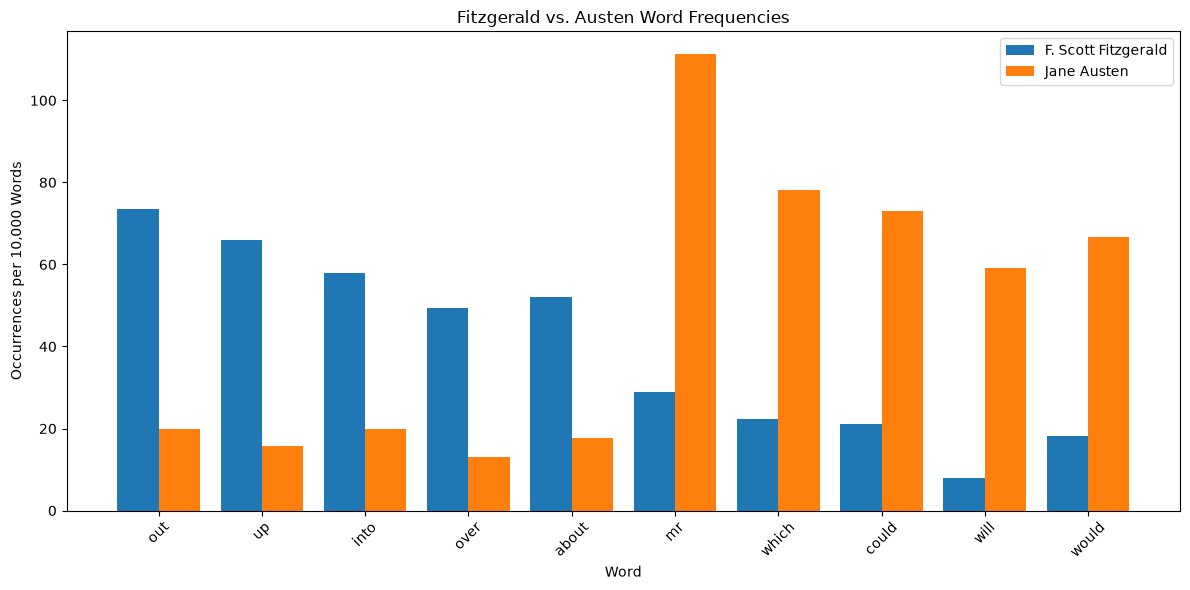

In [13]:
selected_words = fitzgerald_words[:5] + austen_words[:5]

words = [item[0] for item in selected_words]
fitzgerald_rates = [item[1] for item in selected_words]
austen_rates = [item[2] for item in selected_words]

x = list(range(len(words)))

plt.figure(figsize=(12, 6))

plt.bar(
    [i - 0.2 for i in x],
    fitzgerald_rates,
    width=0.4,
    label="F. Scott Fitzgerald"
)

plt.bar(
    [i + 0.2 for i in x],
    austen_rates,
    width=0.4,
    label="Jane Austen"
)

plt.xticks(x, words, rotation=45)

plt.ylabel("Occurrences per 10,000 Words")
plt.xlabel("Word")
plt.title("Fitzgerald vs. Austen Word Frequencies")

plt.legend()
plt.tight_layout()
plt.show()

# 3. Words Preferred by Different Authors

To determine whether one author uses certain words more frequently than
the other, I normalized the frequencies to occurrences per 10,000 words.

This is needed since *The Great Gatsby* and *Pride and Prejudice*
have different total word counts.

I also removed major character names because names are specific to the
story and do not provide a useful comparison of the authors general
word usage.

The results respresent that some words are more frequent
in Fitzgerald's novel while other words are more frequent in
Austen's novel. This suggests that word-frequency analysis can identify
differences in vocabulary choices between the authors.

# Problems Encountered

One problem was that the three books have different lengths. After cleaning
the text, *The Great Gatsby* had 28,998 analyzed words, *This Side of Paradise*
had 50,754, and *Pride and Prejudice* had 72,616. Due to this, comparing
only raw word counts does not make sense. I solved this by comparing occurrences
per 10,000 words.

Another problem was that character names were some of the most frequent words.
For example, "Gatsby" was one of the most common words in *The Great Gatsby*,
"Amory" was the most common in *This Side of Paradise*, and "Elizabeth" and
"Darcy" were common in *Pride and Prejudice*. I removed main character names
when comparing the authors because these names are specific to each story and show up frequently.

I also had to remove other common words so that words such as "the" and "and" dont take over the data since they have no meaning.

# Results

The analysis showed differences in word use between books and authors. *The Great Gatsby* and *This Side of Paradise* shared common words like "him," "all," "out," and "said," but used them at different times. The difference was larger between Fitzgerald and Austen. Fitzgerald used words like "out," "up," and "into" more often, while Austen used words like "mr," "could," "will," and "would" more often. Overall, word frequencies showed clear differences between the authors writing.

# New Ideas

This analysis could be expanded by comparing more books from Fitzgerald and
Austen. This would help determine whether the differences found here are
actually due to the different authors verbage or only relate to *The Great Gatsby* and *Pride and Prejudice*.